# Lab 1 Demo — FashionMNIST Image Classification

**Nhóm 4 | Deep Learning | PyTorch**

Notebook này trình diễn pipeline Lab 1 bằng chính các module và artifact đã có trong repository.

**Luồng demo:** Dataset → Batch/Tensor → MLP → Forward Pass → Một bước Backpropagation → So sánh thực nghiệm → Chọn checkpoint → Prediction → Test metrics → Error analysis.

> **Lưu ý:** Notebook không huấn luyện lại bốn thực nghiệm A/B/C/D và không ghi đè checkpoint cuối. Phần training bên dưới chỉ minh họa một bước cập nhật trên một batch bằng mô hình tạm thời; kết quả thực nghiệm chính thức được đọc từ các file đã lưu.

In [10]:
from pathlib import Path
import os
import sys
import json
import math

# Tìm thư mục gốc để notebook chạy được dù được mở từ root hoặc notebooks/.
_candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(
    (path.resolve() for path in _candidates
     if (path / "main.py").is_file() and (path / "src").is_dir()),
    None,
)
if ROOT is None:
    raise RuntimeError(
        "Không tìm thấy project root. Hãy mở notebook trong repository Lab1_DL_Group4."
    )

os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

print("Project root:", ROOT)
print("Notebook:", Path.cwd() / "notebooks" / "02_lab_demo.ipynb")
print("Project modules:", (ROOT / "src").is_dir())

Project root: D:\learn_DeepLearning\fashionmnist-lab1-final
Notebook: D:\learn_DeepLearning\fashionmnist-lab1-final\notebooks\02_lab_demo.ipynb
Project modules: True


## 1. Environment và cấu hình chạy

Ta sử dụng các tiện ích chung của dự án để đọc môi trường, cố định seed và chọn CPU. CPU được chọn tường minh vì các thực nghiệm Lab 1 đã được chạy trên CPU; điều này giúp notebook không tự chuyển sang một thiết bị khác.

In [11]:
import sys
print("Python đang dùng:", sys.executable)

%pip install torchvision

Python đang dùng: C:\Users\ADMIN\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: C:\Users\ADMIN\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [12]:
import torch
import torchvision
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

from src.utils import (
    collect_environment,
    resolve_device,
    set_seed,
    load_json,
    validate_config,
)
from src.data import build_dataloaders, CLASS_NAMES
from src.model import MLP
from src.predict import load_model, predict_batch

SEED = 42
set_seed(SEED)
device = resolve_device("cpu")

environment = collect_environment()
print("Python:", environment["python"])
print("Platform:", environment["platform"])
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Device:", device)
print("CUDA available:", torch.cuda.is_available())

Python: 3.11.9
Platform: Windows-10-10.0.26200-SP0
PyTorch: 2.14.1+cpu
Torchvision: 0.29.2+cpu
NumPy: 1.26.4
Pandas: 2.3.1
Matplotlib: 3.10.5
Device: cpu
CUDA available: False


## 2. Dataset FashionMNIST và cách chia dữ liệu

FashionMNIST gồm ảnh grayscale kích thước **28 × 28**, thuộc **10 lớp**.

Theo cấu hình của nhóm:
- Train: 54.000 ảnh.
- Validation: 6.000 ảnh.
- Test: 10.000 ảnh.
- Transform: `ToTensor()`, đưa ảnh về tensor `float32` với giá trị pixel trong khoảng [0, 1].
- Batch size: 64.

Train và validation sử dụng chung `outputs/split_indices.json` cho cả bốn thực nghiệm. Tập test được giữ riêng để đánh giá cuối cùng, không tham gia chọn cấu hình.

In [13]:
config = validate_config(load_json(ROOT / "configs" / "D.json"))
split_path = ROOT / config["split_indices_path"]
if not split_path.is_file():
    raise FileNotFoundError(
        f"Thiếu {split_path}. Hãy chạy: python main.py --mode prepare --config configs/A.json"
    )

train_loader, val_loader, test_loader, class_names = build_dataloaders(config)

print("Train samples:", len(train_loader.dataset))
print("Validation samples:", len(val_loader.dataset))
print("Test samples:", len(test_loader.dataset))
print("Number of classes:", len(class_names))
print("Class names:", class_names)

assert len(train_loader.dataset) == 54000
assert len(val_loader.dataset) == 6000
assert len(test_loader.dataset) == 10000
assert len(class_names) == 10

Train samples: 54000
Validation samples: 6000
Test samples: 10000
Number of classes: 10
Class names: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


In [14]:
summary_path = ROOT / "outputs" / "data_summary.json"
if summary_path.is_file():
    data_summary = json.loads(summary_path.read_text(encoding="utf-8"))
    display(pd.Series(data_summary, name="Dataset summary").to_frame())
else:
    print("Chưa có outputs/data_summary.json; thông tin batch sẽ được kiểm tra trực tiếp bên dưới.")

distribution_path = ROOT / "outputs" / "class_distribution.csv"
if distribution_path.is_file():
    class_distribution = pd.read_csv(distribution_path)
    display(class_distribution)
else:
    print("Chưa có outputs/class_distribution.csv.")

,Dataset summary
train_samples,54000
val_samples,6000
test_samples,10000
image_shape,"[1, 28, 28]"
batch_image_shape,"[64, 1, 28, 28]"
batch_label_shape,[64]
pixel_min,0.0
pixel_max,1.0
image_dtype,torch.float32
label_dtype,torch.int64


,class_id,class_name,train_count,val_count,test_count
0,0,T-shirt/top,5342,658,1000
1,1,Trouser,5389,611,1000
2,2,Pullover,5388,612,1000
3,3,Dress,5438,562,1000
4,4,Coat,5393,607,1000
5,5,Sandal,5387,613,1000
6,6,Shirt,5400,600,1000
7,7,Sneaker,5463,537,1000
8,8,Bag,5402,598,1000
9,9,Ankle boot,5398,602,1000


### 2.1. Quan sát ảnh mẫu

Hiển thị 12 ảnh từ tập train cùng nhãn tương ứng. Đây là ảnh thật được lấy từ FashionMNIST, không phải ảnh minh họa tự tạo.

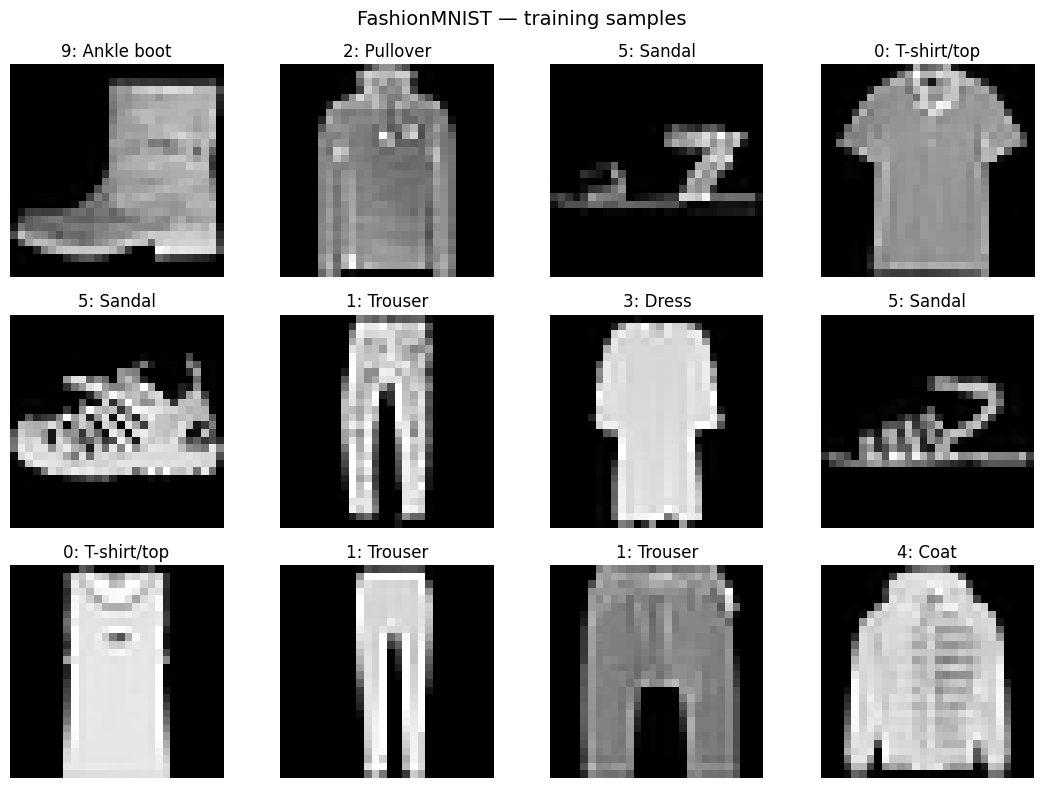

In [15]:
fig, axes = plt.subplots(3, 4, figsize=(11, 8))
for index, ax in enumerate(axes.flat):
    image, label = train_loader.dataset[index]
    ax.imshow(image.squeeze(0), cmap="gray")
    ax.set_title(f"{label}: {class_names[int(label)]}")
    ax.axis("off")

fig.suptitle("FashionMNIST — training samples", fontsize=14)
fig.tight_layout()
plt.show()

### 2.2. Từ ảnh đơn đến batch tensor

Một ảnh có shape `[1, 28, 28]`. Khi gom 64 ảnh thành batch, shape trở thành `[64, 1, 28, 28]`.

- Trục 0: số ảnh trong batch (B).
- Trục 1: số kênh màu (grayscale nên bằng 1).
- Trục 2 và 3: chiều cao và chiều rộng (28 × 28).

In [16]:
images, labels = next(iter(train_loader))

print("Images shape:", tuple(images.shape))
print("Labels shape:", tuple(labels.shape))
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)
print("Pixel range:", (float(images.min()), float(images.max())))
print("First 12 labels:", labels[:12].tolist())

assert images.shape[1:] == (1, 28, 28)
assert labels.ndim == 1
assert images.dtype == torch.float32
assert labels.dtype == torch.int64

Images shape: (64, 1, 28, 28)
Labels shape: (64,)
Image dtype: torch.float32
Label dtype: torch.int64
Pixel range: (0.0, 1.0)
First 12 labels: [9, 3, 3, 9, 0, 0, 9, 7, 6, 5, 0, 6]


2.3. EDA — phân bố lớp và kiểm tra cách chia tập
Đếm nhãn trực tiếp từ dataset và các chỉ số split đã lưu, sau đó so sánh tỷ lệ (%) giữa train, validation và test vì ba tập có kích thước khác nhau. Kiểm tra train/validation không trùng chỉ số và phủ đủ tập train gốc. Đây là kiểm tra cách chia dữ liệu, không phải kiểm tra ảnh trùng nội dung.

Thống kê test chỉ mô tả tập đánh giá đã có; không dùng để điều chỉnh cấu hình hoặc chọn mô hình.

,train,validation,test
class_name,,,
T-shirt/top,5342,658,1000
Trouser,5389,611,1000
Pullover,5388,612,1000
Dress,5438,562,1000
Coat,5393,607,1000
Sandal,5387,613,1000
Shirt,5400,600,1000
Sneaker,5463,537,1000
Bag,5402,598,1000


,train (%),validation (%),test (%)
class_name,,,
T-shirt/top,9.89,10.97,10.0
Trouser,9.98,10.18,10.0
Pullover,9.98,10.20,10.0
Dress,10.07,9.37,10.0
Coat,9.99,10.12,10.0
Sandal,9.98,10.22,10.0
Shirt,10.00,10.00,10.0
Sneaker,10.12,8.95,10.0
Bag,10.00,9.97,10.0


PASS: train/validation không trùng chỉ số và phủ đủ tập train gốc.


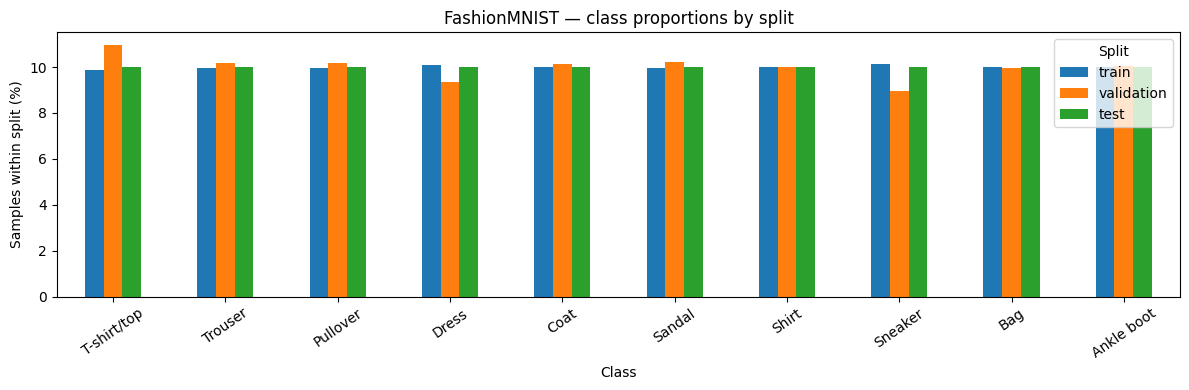

train: min=5342, max=5463, max/min=1.023
validation: min=537, max=658, max/min=1.225
test: min=1000, max=1000, max/min=1.000
Đối chiếu tỷ lệ các lớp để nhận xét cân bằng; không suy ra chất lượng mô hình từ biểu đồ này.


In [31]:
# Dùng đúng Subset do pipeline tạo, không chia dữ liệu lại.
eda_train = train_loader.dataset
eda_val = val_loader.dataset
eda_test = test_loader.dataset
eda_train_indices = np.asarray(eda_train.indices, dtype=np.int64)
eda_val_indices = np.asarray(eda_val.indices, dtype=np.int64)
assert eda_train.dataset is eda_val.dataset
assert np.unique(eda_train_indices).size == eda_train_indices.size
assert np.unique(eda_val_indices).size == eda_val_indices.size
assert np.intersect1d(eda_train_indices, eda_val_indices).size == 0
assert np.array_equal(
    np.sort(np.concatenate([eda_train_indices, eda_val_indices])),
    np.arange(len(eda_train.dataset)),
)
eda_targets = np.asarray(eda_train.dataset.targets, dtype=np.int64)
eda_labels = {
    "train": eda_targets[eda_train_indices],
    "validation": eda_targets[eda_val_indices],
    "test": np.asarray(eda_test.targets, dtype=np.int64),
}
eda_counts = pd.DataFrame(index=pd.Index(class_names, name="class_name"))
for split_name, split_labels in eda_labels.items():
    assert np.isin(split_labels, np.arange(len(class_names))).all()
    eda_counts[split_name] = np.bincount(
        split_labels, minlength=len(class_names)
    )
eda_percentages = eda_counts.div(eda_counts.sum(axis=0), axis=1) * 100
display(eda_counts)
display(eda_percentages.round(2).rename(
    columns=lambda name: name + " (%)"
))
print("PASS: train/validation không trùng chỉ số và phủ đủ tập train gốc.")

ax = eda_percentages.plot.bar(figsize=(12, 4), rot=35)
ax.set_title("FashionMNIST — class proportions by split")
ax.set_xlabel("Class")
ax.set_ylabel("Samples within split (%)")
ax.legend(title="Split")
plt.tight_layout()
plt.show()

for split_name in eda_counts.columns:
    smallest = int(eda_counts[split_name].min())
    largest = int(eda_counts[split_name].max())
    print(f"{split_name}: min={smallest}, max={largest}, max/min={largest / smallest:.3f}")
print("Đối chiếu tỷ lệ các lớp để nhận xét cân bằng; không suy ra chất lượng mô hình từ biểu đồ này.")

2.4. EDA — giá trị pixel và ảnh đại diện 10 lớp
Chọn cố định tối đa 2.048 ảnh train để khảo sát pixel sau transform ToTensor(). Min, max, mean, standard deviation và histogram dưới đây chỉ đại diện cho mẫu khảo sát này; không phải thống kê toàn bộ dữ liệu. Không dùng thống kê này để thay đổi tiền xử lý của checkpoint đã huấn luyện.

Ảnh nền tối có thể tạo nhiều pixel gần 0. Ảnh của một số lớp áo có hình dáng tương tự; quan sát này giúp đặt câu hỏi khi phân tích lỗi, chưa chứng minh mô hình nhầm lớp nào.

,Train sample pixel statistics
sampled_train_images,2048.000000
pixel_min,0.000000
pixel_max,1.000000
pixel_mean,0.285685
pixel_std_population,0.352839


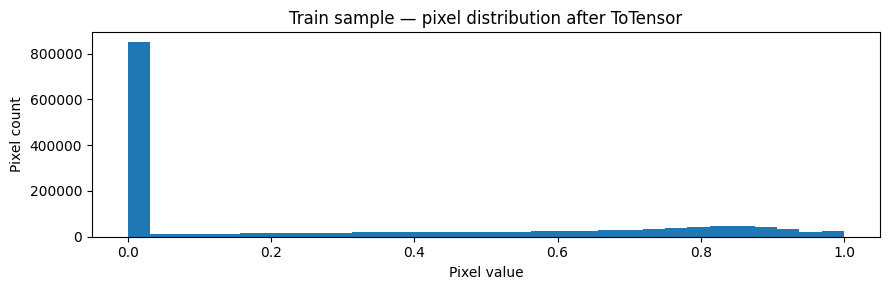

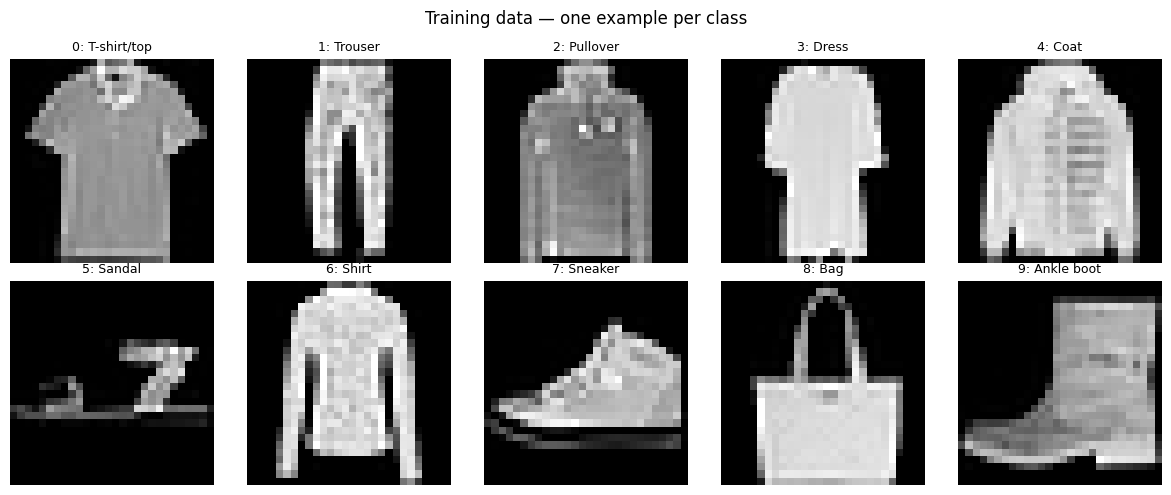

In [32]:
# Generator riêng: không tiêu thụ RNG của DataLoader hoặc thay đổi seed huấn luyện.
eda_rng = np.random.default_rng(SEED)
eda_sample_indices = eda_rng.choice(
    len(eda_train), size=min(2048, len(eda_train)), replace=False
)
eda_pixels = np.stack([
    eda_train[int(index)][0].numpy() for index in eda_sample_indices
])
assert eda_pixels.shape[1:] == (1, 28, 28)
assert eda_pixels.dtype == np.float32
assert np.isfinite(eda_pixels).all()
assert 0 <= eda_pixels.min() <= eda_pixels.max() <= 1
display(pd.Series({
    "sampled_train_images": len(eda_sample_indices),
    "pixel_min": float(eda_pixels.min()),
    "pixel_max": float(eda_pixels.max()),
    "pixel_mean": float(eda_pixels.mean()),
    "pixel_std_population": float(eda_pixels.std()),
}, name="Train sample pixel statistics").to_frame())

fig, ax = plt.subplots(figsize=(9, 3))
ax.hist(eda_pixels.reshape(-1), bins=32, range=(0, 1))
ax.set(title="Train sample — pixel distribution after ToTensor",
       xlabel="Pixel value", ylabel="Pixel count")
plt.tight_layout()
plt.show()

# Mỗi lớp lấy một ảnh từ train; không lấy ảnh test để trình diễn dữ liệu học.
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for class_id, ax in enumerate(axes.flat):
    subset_index = int(np.flatnonzero(eda_labels["train"] == class_id)[0])
    image, label = eda_train[subset_index]
    ax.imshow(image.squeeze(0).numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"{int(label)}: {class_names[int(label)]}", fontsize=9)
    ax.axis("off")
fig.suptitle("Training data — one example per class")
fig.tight_layout()
plt.show()

## 3. Kiến trúc MLP

Mô hình của nhóm là **Multi-Layer Perceptron (MLP)** gồm:

`Input → Flatten → Linear(784, H) → ReLU → Linear(H, 10) → Logits`

- **Flatten:** chuyển mỗi ảnh từ `[1, 28, 28]` thành vector 784 phần tử; không gộp các ảnh trong batch với nhau.
- **Linear(784, H):** học H đặc trưng ẩn từ 784 pixel.
- **ReLU:** tạo tính phi tuyến.
- **Linear(H, 10):** tạo 10 logits, tương ứng 10 lớp.

Không đặt Softmax ở cuối model vì CrossEntropyLoss nhận logits trực tiếp.

In [17]:
model = MLP(hidden_units=256).to(device)
print(model)

def count_parameters(module):
    return sum(parameter.numel() for parameter in module.parameters()
               if parameter.requires_grad)

for hidden_units in (128, 256):
    candidate = MLP(hidden_units=hidden_units)
    print(
        f"hidden_units={hidden_units}: "
        f"{count_parameters(candidate):,} trainable parameters"
    )

assert count_parameters(MLP(hidden_units=128)) == 101770
assert count_parameters(MLP(hidden_units=256)) == 203530

MLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=784, out_features=256, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=256, out_features=10, bias=True)
)
hidden_units=128: 101,770 trainable parameters
hidden_units=256: 203,530 trainable parameters


## 4. Demo Forward Pass — dữ liệu đi qua từng lớp

Đây là phần quan trọng để quan sát cách một batch ảnh đi qua mạng neural network.

Với batch đầu vào `[B, 1, 28, 28]`:
1. Flatten biến mỗi ảnh thành 784 giá trị.
2. Linear thứ nhất biến 784 đặc trưng thành H đặc trưng.
3. ReLU áp dụng hàm kích hoạt.
4. Linear cuối tạo 10 logits cho mỗi ảnh.

Ta gọi trực tiếp từng module con của chính `MLP` trong `src/model.py`, sau đó đối chiếu với kết quả gọi `model(images)`.

In [18]:
model.eval()
demo_images = images.to(device)

with torch.no_grad():
    x0 = demo_images
    x1 = model.flatten(x0)
    x2 = model.fc1(x1)
    x3 = model.relu(x2)
    x4 = model.fc2(x3)
    full_logits = model(demo_images)

print(f"Input       : {tuple(x0.shape)}")
print(f"After Flatten: {tuple(x1.shape)}")
print(f"After Linear1: {tuple(x2.shape)}")
print(f"After ReLU   : {tuple(x3.shape)}")
print(f"Output logits: {tuple(x4.shape)}")
print("Full model output:", tuple(full_logits.shape))
print("All logits finite:", bool(torch.isfinite(full_logits).all()))

assert x1.shape == (images.shape[0], 784)
assert x2.shape == (images.shape[0], 256)
assert x3.shape == (images.shape[0], 256)
assert x4.shape == (images.shape[0], 10)
assert torch.allclose(x4, full_logits, rtol=1e-5, atol=1e-6)

Input       : (64, 1, 28, 28)
After Flatten: (64, 784)
After Linear1: (64, 256)
After ReLU   : (64, 256)
Output logits: (64, 10)
Full model output: (64, 10)
All logits finite: True


### 4.1. Logits, xác suất và lớp dự đoán

Logits là điểm số thô của 10 lớp. Dùng Softmax để chuyển logits thành phân phối xác suất khi cần diễn giải kết quả.

`predicted_class = argmax(logits)`

**Lưu ý:** model ở phần này vừa được khởi tạo ngẫu nhiên, chỉ dùng minh họa Forward Pass. Dự đoán chính thức sẽ được thực hiện bằng checkpoint đã huấn luyện ở phần sau.

In [19]:
with torch.no_grad():
    probabilities = torch.softmax(full_logits, dim=1)
    predicted_labels = probabilities.argmax(dim=1)

sample_index = 0
print("True label:", int(labels[sample_index]), class_names[int(labels[sample_index])])
print("Predicted label (untrained demo model):",
      int(predicted_labels[sample_index]),
      class_names[int(predicted_labels[sample_index])])
print("Probability sum:",
      float(probabilities[sample_index].sum()))
print("Top-3 class probabilities:")
top_values, top_indices = probabilities[sample_index].topk(3)
for value, index in zip(top_values.tolist(), top_indices.tolist()):
    print(f"  {class_names[index]}: {value:.4f}")

True label: 9 Ankle boot
Predicted label (untrained demo model): 2 Pullover
Probability sum: 1.0
Top-3 class probabilities:
  Pullover: 0.1147
  Dress: 0.1111
  Coat: 0.1048


## 5. Demo Training — Loss, Backpropagation và Optimizer

Một vòng cập nhật trọng số cơ bản gồm:

1. Đưa batch qua model để tính logits (**forward**).
2. So sánh logits với nhãn thật bằng Cross-Entropy Loss.
3. Gọi `loss.backward()` để tính gradient (**backpropagation**).
4. Optimizer Adam cập nhật tham số bằng `optimizer.step()`.

Cell kế tiếp chỉ chạy **một bước cập nhật trên một batch** bằng model tạm thời. Nó minh họa cơ chế training, không phải quá trình huấn luyện 10 epochs và không thay đổi checkpoint D đã bàn giao.

In [20]:
set_seed(SEED)
training_demo_model = MLP(hidden_units=128).to(device)
optimizer = torch.optim.Adam(training_demo_model.parameters(), lr=0.001)
loss_fn = torch.nn.CrossEntropyLoss()

demo_batch_images = images.to(device)
demo_batch_labels = labels.to(device)

weight_before = training_demo_model.fc1.weight.detach().clone()

training_demo_model.train()
optimizer.zero_grad(set_to_none=True)

demo_logits = training_demo_model(demo_batch_images)
demo_loss = loss_fn(demo_logits, demo_batch_labels)
demo_loss.backward()

gradient_norm = training_demo_model.fc1.weight.grad.norm().item()
optimizer.step()

weight_after = training_demo_model.fc1.weight.detach()
weights_changed = not torch.equal(weight_before, weight_after)

print("Batch size:", len(demo_batch_labels))
print("Logits shape:", tuple(demo_logits.shape))
print("Cross-Entropy loss (one demo batch):", round(demo_loss.item(), 6))
print("Gradient norm (fc1.weight):", round(gradient_norm, 6))
print("Weights changed after Adam step:", weights_changed)

assert torch.isfinite(demo_loss)
assert gradient_norm > 0
assert weights_changed

Batch size: 64
Logits shape: (64, 10)
Cross-Entropy loss (one demo batch): 2.30122
Gradient norm (fc1.weight): 0.913596
Weights changed after Adam step: True


## 6. So sánh bốn thực nghiệm A/B/C/D

Nhóm khảo sát ảnh hưởng của Learning Rate và số neuron tầng ẩn. Các run dùng chung seed, split, batch size và số epochs; mỗi run thay đổi cấu hình theo kế hoạch.

- **A — Baseline:** H=128, learning rate=0.001.
- **B — LR nhỏ:** H=128, learning rate=0.0001.
- **C — LR lớn:** H=128, learning rate=0.01.
- **D — Mạng rộng hơn:** H=256, learning rate=0.001.

Ta đọc kết quả đã lưu trong `outputs/experiment_results.csv`; không train lại các run.

In [21]:
results_path = ROOT / "outputs" / "experiment_results.csv"
if not results_path.is_file():
    raise FileNotFoundError("Thiếu outputs/experiment_results.csv")

experiment_results = pd.read_csv(results_path)
display(
    experiment_results[
        [
            "run_id", "hidden_units", "learning_rate", "batch_size",
            "epochs", "best_epoch", "best_val_accuracy", "best_val_loss",
        ]
    ].style.format({
        "learning_rate": "{:.4g}",
        "best_val_accuracy": "{:.4%}",
        "best_val_loss": "{:.4f}",
    })
)

,run_id,hidden_units,learning_rate,batch_size,epochs,best_epoch,best_val_accuracy,best_val_loss
0,A,128,0.001,64,10,10,88.4500%,0.3198
1,B,128,0.0001,64,10,10,85.9667%,0.4021
2,C,128,0.01,64,10,5,87.1667%,0.3689
3,D,256,0.001,64,10,9,88.8333%,0.3001


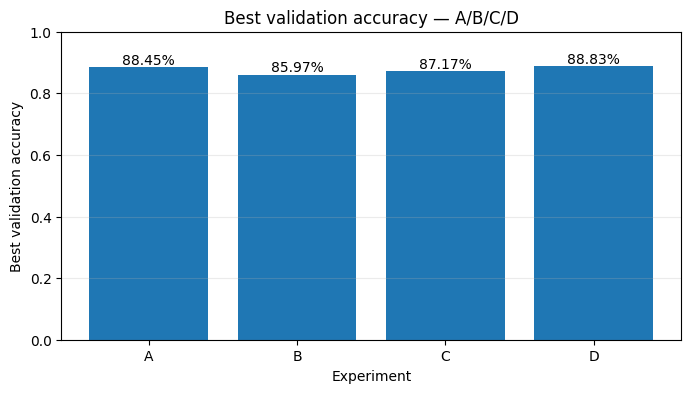

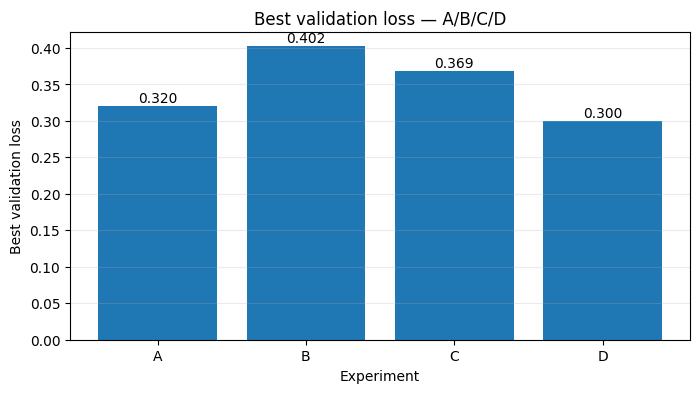

In [22]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(experiment_results["run_id"], experiment_results["best_val_accuracy"])
ax.set_ylim(0, 1)
ax.set_xlabel("Experiment")
ax.set_ylabel("Best validation accuracy")
ax.set_title("Best validation accuracy — A/B/C/D")
for index, value in enumerate(experiment_results["best_val_accuracy"]):
    ax.text(index, value + 0.01, f"{value:.2%}", ha="center")
ax.grid(axis="y", alpha=0.25)
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(experiment_results["run_id"], experiment_results["best_val_loss"])
ax.set_xlabel("Experiment")
ax.set_ylabel("Best validation loss")
ax.set_title("Best validation loss — A/B/C/D")
for index, value in enumerate(experiment_results["best_val_loss"]):
    ax.text(index, value + 0.005, f"{value:.3f}", ha="center")
ax.grid(axis="y", alpha=0.25)
plt.show()

### 6.1. Quan sát lịch sử huấn luyện của Run D

Biểu đồ bên dưới được dựng từ `outputs/runs/D/history.csv`. Loss train giảm qua các epoch; validation loss được dùng để theo dõi khả năng tổng quát hóa và lựa chọn epoch tốt nhất.

,epoch,train_loss,train_accuracy,val_loss,val_accuracy
0,1,0.5344,81.51%,0.4197,85.35%
1,2,0.3916,85.92%,0.4214,85.25%
2,3,0.3486,87.31%,0.3530,87.10%
3,4,0.3229,88.23%,0.3367,87.53%
4,5,0.3017,88.89%,0.3352,87.38%
5,6,0.2867,89.44%,0.3191,88.48%
6,7,0.2732,89.81%,0.3191,87.82%
7,8,0.2586,90.47%,0.3095,88.57%
8,9,0.2496,90.66%,0.3001,88.83%
9,10,0.2399,91.11%,0.3187,88.63%


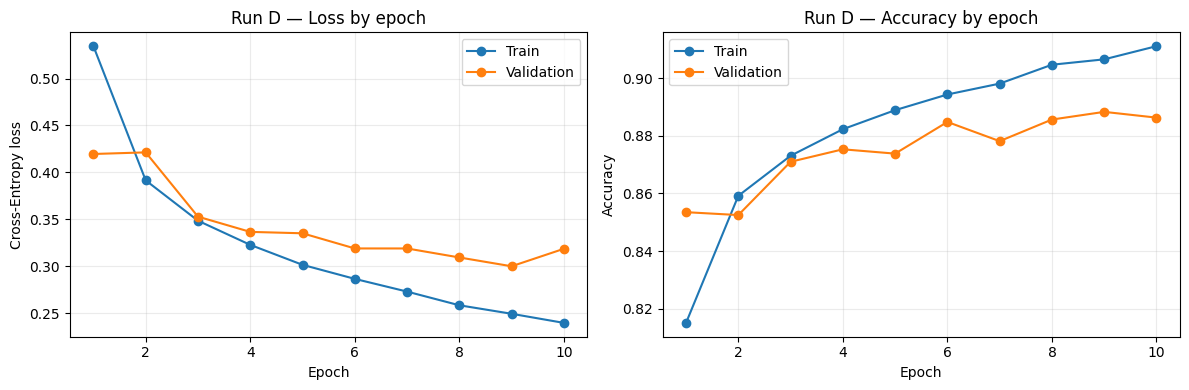

In [23]:
history_path = ROOT / "outputs" / "runs" / "D" / "history.csv"
if not history_path.is_file():
    raise FileNotFoundError("Thiếu outputs/runs/D/history.csv")

history_D = pd.read_csv(history_path)
display(history_D.style.format({
    "train_loss": "{:.4f}",
    "train_accuracy": "{:.2%}",
    "val_loss": "{:.4f}",
    "val_accuracy": "{:.2%}",
}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_D["epoch"], history_D["train_loss"], marker="o", label="Train")
axes[0].plot(history_D["epoch"], history_D["val_loss"], marker="o", label="Validation")
axes[0].set_title("Run D — Loss by epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy loss")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(history_D["epoch"], history_D["train_accuracy"], marker="o", label="Train")
axes[1].plot(history_D["epoch"], history_D["val_accuracy"], marker="o", label="Validation")
axes[1].set_title("Run D — Accuracy by epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.25)

fig.tight_layout()
plt.show()

## 7. Model Selection — Vì sao chọn Run D, Epoch 9?

Việc lựa chọn chỉ dựa trên validation:
1. Ưu tiên `best_val_accuracy` cao nhất.
2. Nếu bằng nhau, chọn `best_val_loss` thấp hơn.
3. Nếu tiếp tục hòa, giữ run xuất hiện trước trong danh sách đầu vào.

Tập test **không được sử dụng** để chọn run hoặc epoch.

In [24]:
selection_path = ROOT / "outputs" / "final" / "selection.json"
selection = json.loads(selection_path.read_text(encoding="utf-8"))

display(pd.Series(selection, name="Selected checkpoint").to_frame())

selected_row = experiment_results.loc[
    experiment_results["run_id"] == selection["run_id"]
].iloc[0]

print("Selected run:", selection["run_id"])
print("Selected epoch:", selection["best_epoch"])
print("Best validation accuracy:", f"{selection['val_metrics']['accuracy']:.4%}")
print("Best validation loss:", f"{selection['val_metrics']['loss']:.6f}")

assert selection["run_id"] == "D"
assert int(selection["best_epoch"]) == 9
assert math.isclose(
    float(selected_row["best_val_accuracy"]),
    float(selection["val_metrics"]["accuracy"]),
    rel_tol=0,
    abs_tol=1e-12,
)
assert math.isclose(
    float(selected_row["best_val_loss"]),
    float(selection["val_metrics"]["loss"]),
    rel_tol=0,
    abs_tol=1e-12,
)
print("PASS: selection.json khớp experiment_results.csv.")

,Selected checkpoint
run_id,D
best_epoch,9
checkpoint_path,D:\learn_DeepLearning\fashionmnist-lab1-final\...
val_metrics,"{'loss': 0.3001373190085093, 'accuracy': 0.888..."
criterion,"highest best_val_accuracy, lowest best_val_loss"


Selected run: D
Selected epoch: 9
Best validation accuracy: 88.8333%
Best validation loss: 0.300137
PASS: selection.json khớp experiment_results.csv.


## 8. Nạp checkpoint cuối

Bây giờ ta chuyển từ model khởi tạo ngẫu nhiên sang model đã được huấn luyện.

Checkpoint `outputs/final/best_model.pth` chứa:
- `model_state_dict`: trọng số đã học.
- `model_config`: cấu hình MLP.
- `class_names` và preprocessing.
- Metadata về run, epoch và validation metrics.

Hàm `load_model` của dự án tái tạo kiến trúc, nạp trọng số và chuyển model sang chế độ `eval()`.

In [25]:
checkpoint_path = ROOT / "outputs" / "final" / "best_model.pth"
if not checkpoint_path.is_file():
    raise FileNotFoundError("Không tìm thấy outputs/final/best_model.pth")

trained_model, checkpoint_metadata = load_model(checkpoint_path, device)

print("Run ID:", checkpoint_metadata["run_id"])
print("Epoch:", checkpoint_metadata["epoch"])
print("Model config:", checkpoint_metadata["model_config"])
print("Validation metrics:", checkpoint_metadata["val_metrics"])
print("Trainable parameters:", f"{count_parameters(trained_model):,}")
print("Model mode:", "eval" if not trained_model.training else "train")

assert checkpoint_metadata["run_id"] == "D"
assert checkpoint_metadata["epoch"] == 9
assert count_parameters(trained_model) == 203530
assert not trained_model.training

Run ID: D
Epoch: 9
Model config: {'model_name': 'mlp', 'hidden_units': 256}
Validation metrics: {'loss': 0.3001373190085093, 'accuracy': 0.8883333333333333}
Trainable parameters: 203,530
Model mode: eval


## 9. Prediction Demo — Dự đoán ảnh bằng checkpoint đã huấn luyện

Lấy 12 ảnh đầu tiên từ test dataset theo đúng thứ tự. Dùng `predict_batch` để lấy logits và nhãn dự đoán.

Đây là demo suy luận trên một nhóm ảnh, không huấn luyện lại model.

Input batch: (12, 1, 28, 28)
Logits: (12, 10)
True labels: [9, 2, 1, 1, 6, 1, 4, 6, 5, 7, 4, 5]
Predicted labels: [9, 2, 1, 1, 6, 1, 4, 6, 5, 7, 4, 5]


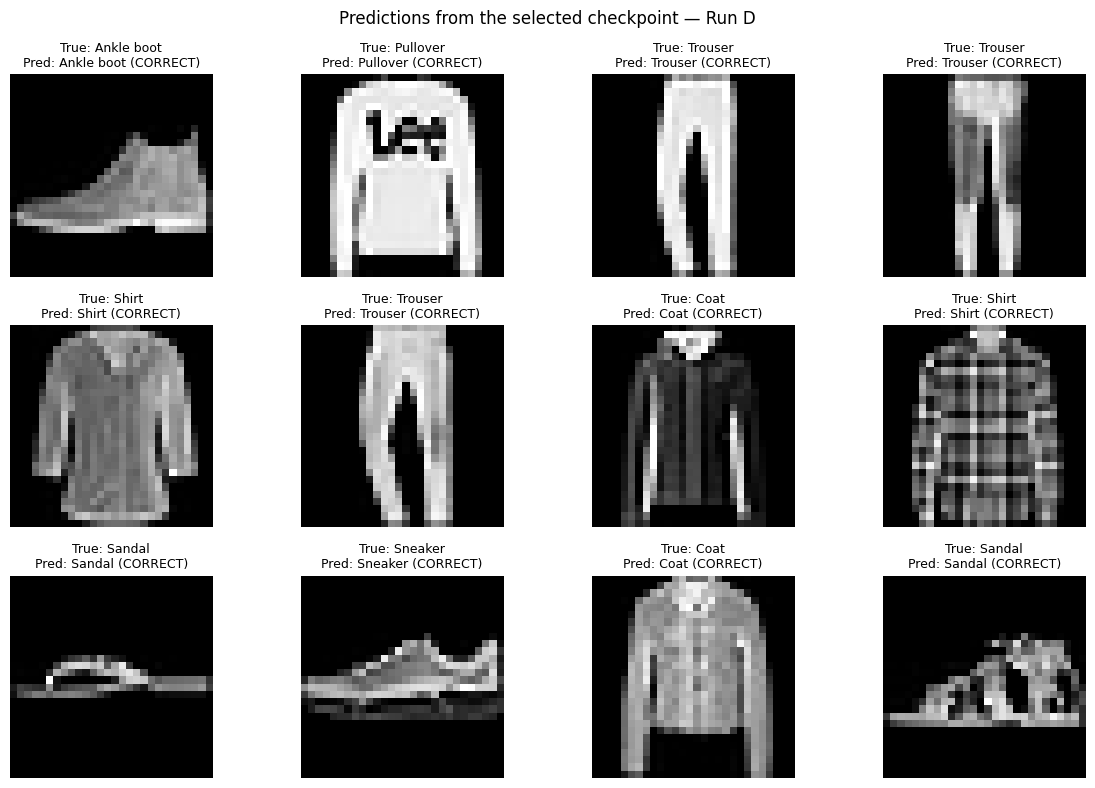

In [26]:
test_images = []
test_true_labels = []
for index in range(12):
    image, label = test_loader.dataset[index]
    test_images.append(image)
    test_true_labels.append(int(label))

test_images = torch.stack(test_images)
prediction_output = predict_batch(trained_model, test_images, device)
test_predicted_labels = prediction_output["labels"].tolist()

print("Input batch:", tuple(test_images.shape))
print("Logits:", tuple(prediction_output["logits"].shape))
print("True labels:", test_true_labels)
print("Predicted labels:", test_predicted_labels)

fig, axes = plt.subplots(3, 4, figsize=(12, 8))
for index, ax in enumerate(axes.flat):
    actual = test_true_labels[index]
    predicted = test_predicted_labels[index]
    ax.imshow(test_images[index].squeeze(0), cmap="gray")
    status = "CORRECT" if actual == predicted else "INCORRECT"
    ax.set_title(
        f"True: {class_names[actual]}\nPred: {class_names[predicted]} ({status})",
        fontsize=9,
    )
    ax.axis("off")

fig.suptitle("Predictions from the selected checkpoint — Run D")
fig.tight_layout()
plt.show()

## 10. Kết quả đánh giá trên Test Set

Kết quả dưới đây được đọc từ `outputs/final/test_metrics.json`, là artifact của lần đánh giá cuối đã thực hiện sau khi chọn checkpoint.

- Test set có 10.000 ảnh.
- Test accuracy: **88.11%**.
- Test loss: **0.3258067**.

Không chạy lại đánh giá toàn bộ test set trong notebook này, nhằm giữ nguyên artifact và tránh thực hiện một lần đánh giá trùng lặp.

In [27]:
metrics_path = ROOT / "outputs" / "final" / "test_metrics.json"
test_metrics = json.loads(metrics_path.read_text(encoding="utf-8"))

metrics_table = pd.DataFrame(
    [
        ["Test loss", test_metrics["loss"]],
        ["Test accuracy", test_metrics["accuracy"]],
        ["Test accuracy (%)", test_metrics["accuracy"] * 100],
        ["Number of test samples", test_metrics["num_samples"]],
        ["Selected run", test_metrics["run_id"]],
        ["Selected epoch", test_metrics["epoch"]],
    ],
    columns=["Metric", "Value"],
)
display(metrics_table)

correct_count = round(test_metrics["accuracy"] * test_metrics["num_samples"])
print(f"Correct predictions (derived from saved accuracy): {correct_count:,}/{test_metrics['num_samples']:,}")
print(f"Test accuracy: {test_metrics['accuracy']:.2%}")

assert test_metrics["run_id"] == "D"
assert test_metrics["epoch"] == 9
assert test_metrics["num_samples"] == 10000
assert math.isclose(test_metrics["accuracy"], 0.8811, abs_tol=1e-12)

,Metric,Value
0,Test loss,0.325807
1,Test accuracy,0.8811
2,Test accuracy (%),88.11
3,Number of test samples,10000
4,Selected run,D
5,Selected epoch,9


Correct predictions (derived from saved accuracy): 8,811/10,000
Test accuracy: 88.11%


## 11. Error Analysis — Quan sát các dự đoán sai

Accuracy cho biết tỷ lệ dự đoán đúng trên toàn bộ test set, nhưng không cho biết những mẫu nào bị nhầm.

Ta đọc `outputs/final/test_predictions.csv` đã được tạo trong lần đánh giá cuối:
- `test_index`: vị trí mẫu trong test dataset.
- `true_label`: nhãn thực tế.
- `predicted_label`: nhãn model dự đoán.

Các chỉ số này chỉ phục vụ phân tích sau khi model đã được chọn; không dùng để thay đổi lựa chọn checkpoint.

In [28]:
predictions_path = ROOT / "outputs" / "final" / "test_predictions.csv"
test_predictions = pd.read_csv(predictions_path)

required_columns = {"test_index", "true_label", "predicted_label"}
if not required_columns.issubset(test_predictions.columns):
    raise ValueError(f"CSV thiếu cột: {required_columns - set(test_predictions.columns)}")

wrong_predictions = test_predictions[
    test_predictions["true_label"] != test_predictions["predicted_label"]
].copy()

print("Total test predictions:", len(test_predictions))
print("Misclassified samples:", len(wrong_predictions))
print("Misclassification rate:", f"{len(wrong_predictions) / len(test_predictions):.2%}")
display(wrong_predictions.head(10))

Total test predictions: 10000
Misclassified samples: 1189
Misclassification rate: 11.89%


,test_index,true_label,predicted_label
12,12,7,5
17,17,4,2
23,23,9,5
25,25,4,2
29,29,3,4
40,40,6,0
42,42,3,6
48,48,2,6
49,49,2,6
51,51,4,2


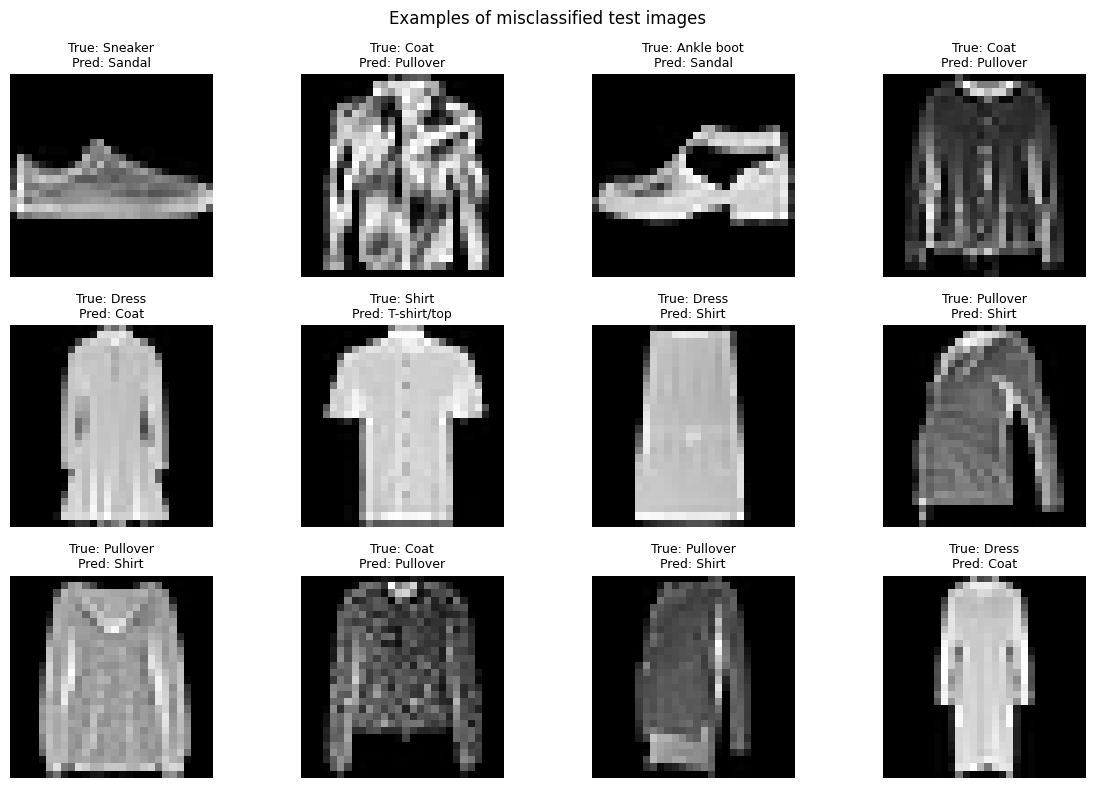

In [29]:
wrong_indices = wrong_predictions["test_index"].astype(int).head(12).tolist()

if wrong_indices:
    wrong_images = []
    wrong_true_labels = []
    for index in wrong_indices:
        image, label = test_loader.dataset[index]
        wrong_images.append(image)
        wrong_true_labels.append(int(label))

    wrong_images = torch.stack(wrong_images)
    wrong_output = predict_batch(trained_model, wrong_images, device)
    wrong_predicted_labels = wrong_output["labels"].tolist()

    fig, axes = plt.subplots(3, 4, figsize=(12, 8))
    for position, ax in enumerate(axes.flat):
        if position >= len(wrong_indices):
            ax.axis("off")
            continue
        actual = wrong_true_labels[position]
        predicted = wrong_predicted_labels[position]
        ax.imshow(wrong_images[position].squeeze(0), cmap="gray")
        ax.set_title(
            f"True: {class_names[actual]}\nPred: {class_names[predicted]}",
            fontsize=9,
        )
        ax.axis("off")

    fig.suptitle("Examples of misclassified test images")
    fig.tight_layout()
    plt.show()
else:
    print("Không có mẫu dự đoán sai trong danh sách.")

## 12. Tổng kết Demo

Qua notebook, ta đã trình diễn được:

1. **Data:** FashionMNIST, chia train/validation/test và cấu trúc batch.
2. **Model:** MLP với Flatten, Linear, ReLU và 10 logits.
3. **Forward Pass:** Theo dõi shape tensor qua từng tầng.
4. **Training:** Minh họa Cross-Entropy, Backpropagation và Adam bằng một batch.
5. **Experiments:** So sánh kết quả A/B/C/D từ artifact thực tế.
6. **Selection:** Chọn Run D, Epoch 9 bằng validation metrics.
7. **Inference:** Nạp checkpoint và dự đoán ảnh.
8. **Evaluation:** Đọc test metrics đã lưu và quan sát các mẫu phân loại sai.

**Kết quả chính thức:** Run D, Epoch 9; validation accuracy 88.8333%; test accuracy 88.11% trên 10.000 ảnh.

### Giới hạn

- Notebook không huấn luyện lại A/B/C/D.
- Một bước training demo không đại diện cho kết quả huấn luyện 10 epochs.
- Test metrics được đọc từ artifact đã lưu, không tính lại.
- MLP Flatten không khai thác cấu trúc không gian ảnh tường minh như CNN.

In [30]:
required_artifacts = [
    ROOT / "outputs" / "experiment_results.csv",
    ROOT / "outputs" / "runs" / "D" / "history.csv",
    ROOT / "outputs" / "final" / "best_model.pth",
    ROOT / "outputs" / "final" / "selection.json",
    ROOT / "outputs" / "final" / "test_metrics.json",
    ROOT / "outputs" / "final" / "test_predictions.csv",
]
artifact_status = pd.DataFrame({
    "Artifact": [str(path.relative_to(ROOT)) for path in required_artifacts],
    "Exists": [path.is_file() for path in required_artifacts],
})
display(artifact_status)

assert artifact_status["Exists"].all()
assert selection["run_id"] == checkpoint_metadata["run_id"] == test_metrics["run_id"] == "D"
assert selection["best_epoch"] == checkpoint_metadata["epoch"] == test_metrics["epoch"] == 9
print("PASS: Lab 1 demo artifacts, selection and checkpoint metadata are consistent.")

,Artifact,Exists
0,outputs\experiment_results.csv,True
1,outputs\runs\D\history.csv,True
2,outputs\final\best_model.pth,True
3,outputs\final\selection.json,True
4,outputs\final\test_metrics.json,True
5,outputs\final\test_predictions.csv,True


PASS: Lab 1 demo artifacts, selection and checkpoint metadata are consistent.
